# Proyecto de clustering: deserción educativa en Medellín

**Asignatura:** Introducción al Machine Learning  
**Autora:** María Isabel Hernández Bello  
**Institución:** Universidad de Cundinamarca  

## Objetivo
Aplicar y comparar K-means, DBSCAN y clustering jerárquico sobre variables de matrícula y deserción educativa. Se utiliza PCA únicamente para representar visualmente las etiquetas de los clústeres en dos dimensiones.

## Fuente de datos
MEData – Alcaldía de Medellín, conjunto de datos de deserción educativa (2017).

> Ejecuta las celdas en orden. La primera ejecución requiere conexión a internet para descargar el CSV. La semilla de aleatoriedad se fija en 42 para favorecer la reproducibilidad.


## 1. Importación de librerías y configuración

In [1]:
# ==========================================
# 1. IMPORTACIÓN DE LIBRERÍAS
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Preparación de datos
from sklearn.preprocessing import StandardScaler

# Algoritmos de clustering
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering

# Métricas de evaluación
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Clustering jerárquico
from scipy.cluster.hierarchy import dendrogram, linkage

# Reducción de dimensionalidad para visualización
from sklearn.decomposition import PCA

# Configuración de gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Reproducibilidad
SEMILLA = 42

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


## 2. Carga del conjunto de datos

In [2]:
# ==========================================
# 2. CARGA DEL DATASET
# ==========================================

url_datos = "https://medata.app.medellin.gov.co/sites/default/files/distribution/1-011-08-000065/desercion_educativa.csv"

df = pd.read_csv(url_datos, encoding="utf-8")

print("BASE DE DATOS CARGADA CORRECTAMENTE")
print("Número de registros:", df.shape[0])
print("Número de columnas:", df.shape[1])

display(df.head())

BASE DE DATOS CARGADA CORRECTAMENTE
Número de registros: 1134
Número de columnas: 52


,año,codigo_dane,establecimiento_educativo,sector,comuna_establecimiento,sexo,desercion_grado_prejardin,desercion_grado_jardin,desercion_grado_transicion,desercion_grado_1,...,matricula_grado_10,matricula_grado_11,matricula_grado_12,matricula_grado_13,matricula_grado_clei1,matricula_grado_clei2,matricula_grado_clei3,matricula_grado_clei4,matricula_grado_clei5,matricula_grado_clei6
0,2017,105001000001,inst educ jose maria velaz,oficial,2,hombres,0,0,0,2,...,14,17,0,0,0,0,0,0,0,0
1,2017,105001000001,inst educ jose maria velaz,oficial,2,mujeres,0,0,0,3,...,30,21,0,0,0,0,0,0,0,0
2,2017,105001000043,inst educ barrio santa cruz,oficial,2,hombres,0,0,1,4,...,20,23,0,0,3,21,57,41,40,0
3,2017,105001000043,inst educ barrio santa cruz,oficial,2,mujeres,0,0,1,1,...,44,19,0,0,13,10,31,51,28,0
4,2017,105001000094,col comfama - sede aranjuez,no oficial,4,hombres,1,2,0,0,...,0,0,0,0,0,0,0,0,0,0


## 3. Exploración inicial

In [3]:
# ==========================================
# 3. EXPLORACIÓN DEL DATASET
# ==========================================

print("DIMENSIONES DEL DATASET:")
print(df.shape)

print("\nTIPOS DE DATOS:")
print(df.dtypes.value_counts())

print("\nVALORES FALTANTES:")
print(df.isnull().sum().sum())

print("\nREGISTROS DUPLICADOS:")
print(df.duplicated().sum())

print("\nVARIABLES DEL DATASET:")
print(df.columns.tolist())

print("\nINFORMACIÓN GENERAL:")
df.info()

DIMENSIONES DEL DATASET:
(1134, 52)

TIPOS DE DATOS:
int64    49
str       3
Name: count, dtype: int64

VALORES FALTANTES:
0

REGISTROS DUPLICADOS:
0

VARIABLES DEL DATASET:
['año', 'codigo_dane', 'establecimiento_educativo', 'sector', 'comuna_establecimiento', 'sexo', 'desercion_grado_prejardin', 'desercion_grado_jardin', 'desercion_grado_transicion', 'desercion_grado_1', 'desercion_grado_2', 'desercion_grado_3', 'desercion_grado_4', 'desercion_grado_5', 'desercion_escuela_nueva', 'desercion_grado_6', 'desercion_grado_7', 'desercion_grado_8', 'desercion_grado_9', 'desercion_grado_10', 'desercion_grado_11', 'desercion_grado_12', 'desercion_grado_13', 'desercion_grado_clei1', 'desercion_grado_clei2', 'desercion_grado_clei3', 'desercion_grado_clei4', 'desercion_grado_clei5', 'desercion_grado_clei6', 'matricula_grado_pj', 'matricula_grado_jd', 'matricula_grado_transicion', 'matricula_grado_1', 'matricula_grado_2', 'matricula_grado_3', 'matricula_grado_4', 'matricula_grado_5', 'matricula_e

## 4. Selección de variables y eliminación de constantes

In [4]:
# ==========================================
# 4. SELECCIÓN DE VARIABLES PARA CLUSTERING
# ==========================================

# Seleccionar variables de matrícula y deserción
columnas_clustering = [
    columna for columna in df.columns
    if columna.startswith(("desercion_", "matricula_"))
]

# Crear conjunto de datos para clustering
df_clustering = df[columnas_clustering].copy()

print("SELECCIÓN DE VARIABLES")
print("Número de registros:", df_clustering.shape[0])
print("Número de variables:", df_clustering.shape[1])

# Identificar variables constantes
variables_constantes = [
    columna for columna in df_clustering.columns
    if df_clustering[columna].nunique() <= 1
]

print("\nVARIABLES CONSTANTES:")
print(variables_constantes)

# Eliminar variables constantes
df_clustering = df_clustering.drop(
    columns=variables_constantes
)

print("\nDIMENSIONES DESPUÉS DE LA SELECCIÓN:")
print(df_clustering.shape)

print("\nPRIMEROS REGISTROS:")
display(df_clustering.head())

SELECCIÓN DE VARIABLES
Número de registros: 1134
Número de variables: 46

VARIABLES CONSTANTES:
['desercion_grado_12', 'desercion_grado_13']

DIMENSIONES DESPUÉS DE LA SELECCIÓN:
(1134, 44)

PRIMEROS REGISTROS:


,desercion_grado_prejardin,desercion_grado_jardin,desercion_grado_transicion,desercion_grado_1,desercion_grado_2,desercion_grado_3,desercion_grado_4,desercion_grado_5,desercion_escuela_nueva,desercion_grado_6,...,matricula_grado_10,matricula_grado_11,matricula_grado_12,matricula_grado_13,matricula_grado_clei1,matricula_grado_clei2,matricula_grado_clei3,matricula_grado_clei4,matricula_grado_clei5,matricula_grado_clei6
0,0,0,0,2,1,0,0,0,0,0,...,14,17,0,0,0,0,0,0,0,0
1,0,0,0,3,1,1,0,0,0,2,...,30,21,0,0,0,0,0,0,0,0
2,0,0,1,4,4,1,7,2,0,16,...,20,23,0,0,3,21,57,41,40,0
3,0,0,1,1,0,1,1,4,0,9,...,44,19,0,0,13,10,31,51,28,0
4,1,2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 5. Estandarización

In [5]:
# ==========================================
# 5. ESTANDARIZACIÓN DE LOS DATOS
# ==========================================

# Crear el escalador
escalador = StandardScaler()

# Ajustar y transformar los datos
datos_estandarizados = escalador.fit_transform(df_clustering)

# Convertir a DataFrame
df_estandarizado = pd.DataFrame(
    datos_estandarizados,
    columns=df_clustering.columns
)

print("ESTANDARIZACIÓN COMPLETADA")
print("Dimensiones:", df_estandarizado.shape)

print("\nPROMEDIO GENERAL:")
print(round(df_estandarizado.mean().mean(), 4))

print("\nDESVIACIÓN ESTÁNDAR GENERAL:")
print(round(df_estandarizado.std(ddof=0).mean(), 4))

print("\nPRIMEROS REGISTROS ESTANDARIZADOS:")
display(df_estandarizado.head())

ESTANDARIZACIÓN COMPLETADA
Dimensiones: (1134, 44)

PROMEDIO GENERAL:
0.0

DESVIACIÓN ESTÁNDAR GENERAL:
1.0

PRIMEROS REGISTROS ESTANDARIZADOS:


,desercion_grado_prejardin,desercion_grado_jardin,desercion_grado_transicion,desercion_grado_1,desercion_grado_2,desercion_grado_3,desercion_grado_4,desercion_grado_5,desercion_escuela_nueva,desercion_grado_6,...,matricula_grado_10,matricula_grado_11,matricula_grado_12,matricula_grado_13,matricula_grado_clei1,matricula_grado_clei2,matricula_grado_clei3,matricula_grado_clei4,matricula_grado_clei5,matricula_grado_clei6
0,-0.180011,-0.185633,-0.373168,0.519313,0.292852,-0.367014,-0.330010,-0.355073,-0.037589,-0.408557,...,-0.220088,-0.082550,-0.039257,-0.035789,-0.117323,-0.178457,-0.230805,-0.224208,-0.185269,-0.204099
1,-0.180011,-0.185633,-0.373168,0.974766,0.292852,0.359328,-0.330010,-0.355073,-0.037589,0.041908,...,0.125620,0.008357,-0.039257,-0.035789,-0.117323,-0.178457,-0.230805,-0.224208,-0.185269,-0.204099
2,-0.180011,-0.185633,0.208913,1.430219,2.227385,0.359328,3.874842,0.954366,-0.037589,3.195166,...,-0.090447,0.053811,-0.039257,-0.035789,2.163434,2.967193,1.422062,0.672509,0.735997,-0.204099
3,-0.180011,-0.185633,0.208913,0.063860,-0.351992,0.359328,0.270683,2.263805,-0.037589,1.618537,...,0.428114,-0.037096,-0.039257,-0.035789,9.765956,1.319472,0.668123,0.891221,0.459617,-0.204099
4,2.014957,4.948691,-0.373168,-0.391593,-0.351992,-0.367014,-0.330010,-0.355073,-0.037589,-0.408557,...,-0.522582,-0.468905,-0.039257,-0.035789,-0.117323,-0.178457,-0.230805,-0.224208,-0.185269,-0.204099


## 6. Selección de K para K-means: método del codo y Silhouette

,Número de clústeres,Inercia,Silhouette
0,2,39077.2178,0.4220
1,3,32765.4983,0.4435
2,4,28939.6545,0.3361
3,5,26921.1615,0.3358
4,6,25359.2227,0.3440
5,7,23918.5575,0.3529
6,8,22809.3750,0.3621
7,9,21671.1634,0.3353
8,10,20409.3396,0.3337


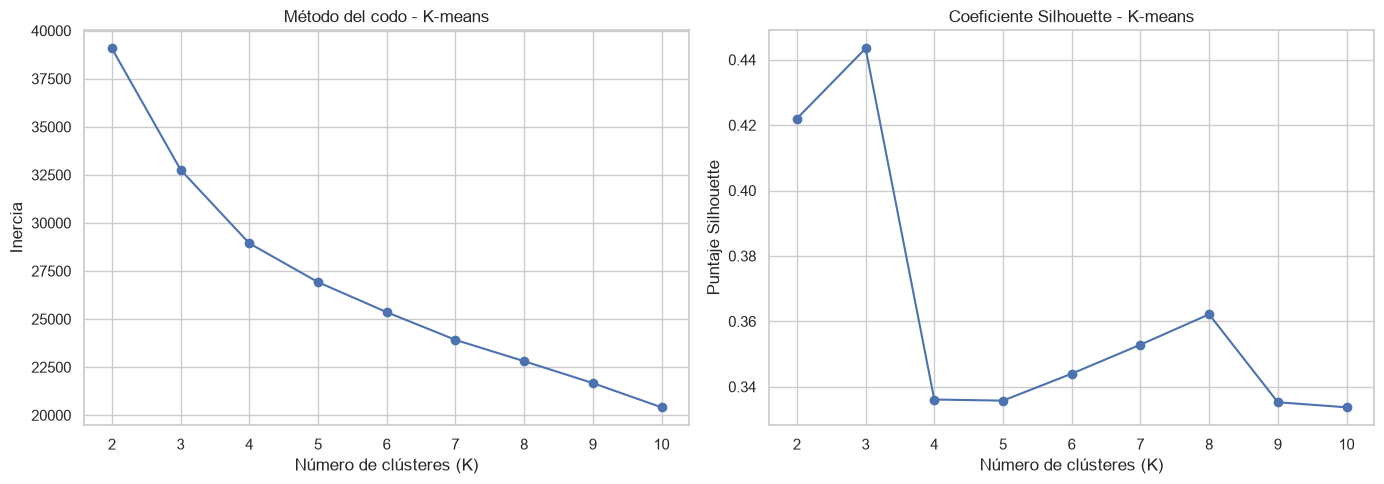

In [6]:
# ==========================================
# 6. SELECCIÓN DEL NÚMERO DE CLÚSTERES
# MÉTODO DEL CODO Y SILHOUETTE
# ==========================================

resultados_kmeans = []

valores_k = range(2, 11)

for k in valores_k:

    modelo = KMeans(
        n_clusters=k,
        random_state=SEMILLA,
        n_init=20
    )

    etiquetas = modelo.fit_predict(df_estandarizado)

    inercia = modelo.inertia_

    silhouette = silhouette_score(
        df_estandarizado,
        etiquetas
    )

    resultados_kmeans.append({
        "Número de clústeres": k,
        "Inercia": inercia,
        "Silhouette": silhouette
    })

# Crear tabla de resultados
tabla_kmeans = pd.DataFrame(resultados_kmeans)

display(tabla_kmeans.round(4))

# Gráficas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Método del codo
axes[0].plot(
    tabla_kmeans["Número de clústeres"],
    tabla_kmeans["Inercia"],
    marker="o"
)

axes[0].set_title("Método del codo - K-means")
axes[0].set_xlabel("Número de clústeres (K)")
axes[0].set_ylabel("Inercia")
axes[0].set_xticks(list(valores_k))

# Silhouette
axes[1].plot(
    tabla_kmeans["Número de clústeres"],
    tabla_kmeans["Silhouette"],
    marker="o"
)

axes[1].set_title("Coeficiente Silhouette - K-means")
axes[1].set_xlabel("Número de clústeres (K)")
axes[1].set_ylabel("Puntaje Silhouette")
axes[1].set_xticks(list(valores_k))

plt.tight_layout()
plt.show()

## 7. Modelo definitivo K-means y evaluación

In [7]:
# ==========================================
# 8. MODELO DEFINITIVO K-MEANS
# ==========================================

# Crear el modelo con 3 clústeres
modelo_kmeans = KMeans(
    n_clusters=3,
    random_state=SEMILLA,
    n_init=20
)

# Asignar los grupos
clusters_kmeans = modelo_kmeans.fit_predict(
    df_estandarizado
)

# Crear una base con los resultados
df_resultados_kmeans = df[
    [
        "establecimiento_educativo",
        "sector",
        "sexo",
        "comuna_establecimiento"
    ]
].copy()

df_resultados_kmeans["cluster_kmeans"] = clusters_kmeans

# Contar registros por clúster
print("DISTRIBUCIÓN DE REGISTROS POR CLÚSTER")

print(
    df_resultados_kmeans["cluster_kmeans"]
    .value_counts()
    .sort_index()
)

# Porcentaje de registros por clúster
print("\nPORCENTAJE POR CLÚSTER")

print(
    (
        df_resultados_kmeans["cluster_kmeans"]
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
)

# Métricas de evaluación
print("\nMÉTRICAS DEL MODELO K-MEANS")

print(
    "Silhouette:",
    round(
        silhouette_score(df_estandarizado, clusters_kmeans),
        4
    )
)

print(
    "Davies-Bouldin:",
    round(
        davies_bouldin_score(df_estandarizado, clusters_kmeans),
        4
    )
)

print(
    "Calinski-Harabasz:",
    round(
        calinski_harabasz_score(df_estandarizado, clusters_kmeans),
        2
    )
)

# Mostrar primeros resultados
print("\nPRIMEROS REGISTROS CLASIFICADOS")

display(df_resultados_kmeans.head(10))

DISTRIBUCIÓN DE REGISTROS POR CLÚSTER
cluster_kmeans
0    839
1    280
2     15
Name: count, dtype: int64

PORCENTAJE POR CLÚSTER
cluster_kmeans
0    73.99
1    24.69
2     1.32
Name: proportion, dtype: float64

MÉTRICAS DEL MODELO K-MEANS
Silhouette: 0.4435
Davies-Bouldin: 1.1627
Calinski-Harabasz: 295.66

PRIMEROS REGISTROS CLASIFICADOS


,establecimiento_educativo,sector,sexo,comuna_establecimiento,cluster_kmeans
0,inst educ jose maria velaz,oficial,hombres,2,0
1,inst educ jose maria velaz,oficial,mujeres,2,0
2,inst educ barrio santa cruz,oficial,hombres,2,1
3,inst educ barrio santa cruz,oficial,mujeres,2,1
4,col comfama - sede aranjuez,no oficial,hombres,4,0
5,col comfama - sede aranjuez,no oficial,mujeres,4,0
6,inst educ cefa,oficial,hombres,10,0
7,inst educ cefa,oficial,mujeres,10,1
8,inst educ jose maria bernal,oficial,hombres,16,0
9,inst educ jose maria bernal,oficial,mujeres,16,0


## 8. Caracterización de los clústeres K-means

In [8]:
# ==========================================
# 10. CARACTERIZACIÓN DE LOS CLÚSTERES
# ==========================================

# Incorporar la clasificación a los datos originales
df_perfiles = df_clustering.copy()
df_perfiles["cluster"] = clusters_kmeans

# Promedios de matrícula y deserción por clúster
perfil_promedios = df_perfiles.groupby("cluster").mean()

print("PROMEDIO DE MATRÍCULA Y DESERCIÓN POR CLÚSTER:")
display(perfil_promedios.round(2))

# Identificar las 10 variables que más diferencian los grupos
diferencias = (
    perfil_promedios.max(axis=0) -
    perfil_promedios.min(axis=0)
).sort_values(ascending=False)

print("\n10 VARIABLES CON MAYORES DIFERENCIAS ENTRE CLÚSTERES:")
display(diferencias.head(10).to_frame("Diferencia entre grupos").round(2))

# Distribución por sector educativo
print("\nDISTRIBUCIÓN POR SECTOR EDUCATIVO:")
display(pd.crosstab(
    df_resultados_kmeans["cluster_kmeans"],
    df_resultados_kmeans["sector"],
    normalize="index"
).round(3) * 100)

# Distribución por sexo
print("\nDISTRIBUCIÓN POR SEXO:")
display(pd.crosstab(
    df_resultados_kmeans["cluster_kmeans"],
    df_resultados_kmeans["sexo"],
    normalize="index"
).round(3) * 100)

PROMEDIO DE MATRÍCULA Y DESERCIÓN POR CLÚSTER:


,desercion_grado_prejardin,desercion_grado_jardin,desercion_grado_transicion,desercion_grado_1,desercion_grado_2,desercion_grado_3,desercion_grado_4,desercion_grado_5,desercion_escuela_nueva,desercion_grado_6,...,matricula_grado_10,matricula_grado_11,matricula_grado_12,matricula_grado_13,matricula_grado_clei1,matricula_grado_clei2,matricula_grado_clei3,matricula_grado_clei4,matricula_grado_clei5,matricula_grado_clei6
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.10,0.09,0.14,0.15,0.08,0.10,0.12,0.11,0.0,0.32,...,10.21,8.75,0.00,0.00,0.02,0.73,3.69,4.92,3.16,4.38
1,0.03,0.02,2.16,3.04,1.98,1.75,1.85,1.86,0.0,6.39,...,67.23,57.23,0.24,0.19,0.57,1.19,7.48,7.99,5.26,5.18
2,0.00,0.00,0.07,0.07,0.00,0.00,0.00,0.00,0.0,0.00,...,2.53,1.87,0.00,0.00,0.00,26.93,255.67,350.93,333.13,329.93



10 VARIABLES CON MAYORES DIFERENCIAS ENTRE CLÚSTERES:


,Diferencia entre grupos
matricula_grado_clei4,346.02
matricula_grado_clei5,329.97
matricula_grado_clei6,325.56
matricula_grado_clei3,251.98
matricula_grado_6,105.66
matricula_grado_7,87.58
matricula_grado_5,81.79
matricula_grado_3,80.17
matricula_grado_4,80.14
matricula_grado_8,78.16



DISTRIBUCIÓN POR SECTOR EDUCATIVO:


sector,cobertura contratada,no oficial,oficial,regimen especial
cluster_kmeans,,,,
0,8.8,66.6,24.3,0.2
1,2.9,6.4,90.7,0.0
2,66.7,33.3,0.0,0.0



DISTRIBUCIÓN POR SEXO:


sexo,hombres,mujeres
cluster_kmeans,,
0,49.6,50.4
1,51.1,48.9
2,53.3,46.7


## 9. Exploración inicial de parámetros DBSCAN

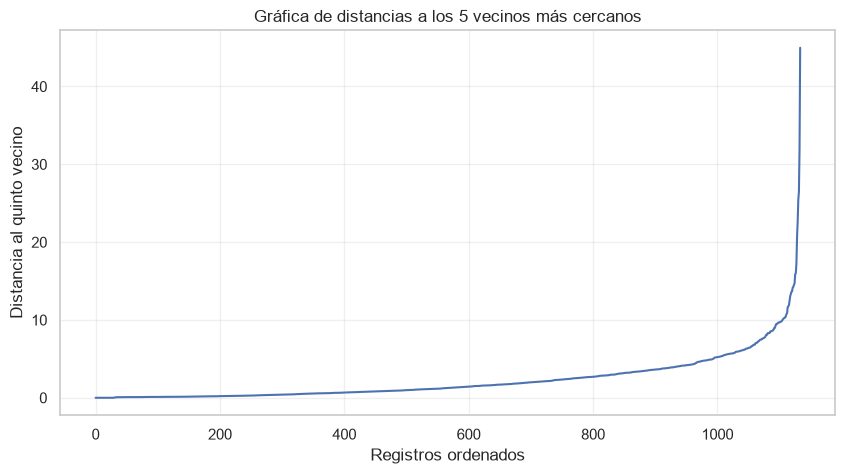

Cantidad de registros analizados: 1134
Distancia mínima: 0.0
Distancia máxima: 44.9745


In [9]:
# ==========================================
# 12. SELECCIÓN INICIAL DE PARÁMETROS DBSCAN
# GRÁFICA DE DISTANCIAS K-NEAREST NEIGHBORS
# ==========================================

from sklearn.neighbors import NearestNeighbors

# Número inicial de vecinos
min_samples_dbscan = 5

# Calcular distancias a los vecinos más cercanos
vecinos = NearestNeighbors(
    n_neighbors=min_samples_dbscan,
    metric="euclidean"
)

vecinos.fit(df_estandarizado)

distancias, indices = vecinos.kneighbors(df_estandarizado)

# Tomar la distancia al quinto vecino
distancias_k = np.sort(distancias[:, -1])

# Graficar distancias ordenadas
plt.figure(figsize=(10, 5))

plt.plot(distancias_k)

plt.title("Gráfica de distancias a los 5 vecinos más cercanos")
plt.xlabel("Registros ordenados")
plt.ylabel("Distancia al quinto vecino")
plt.grid(alpha=0.3)

plt.show()

print("Cantidad de registros analizados:", len(distancias_k))
print("Distancia mínima:", round(distancias_k.min(), 4))
print("Distancia máxima:", round(distancias_k.max(), 4))

## 10. Evaluación de parámetros DBSCAN

In [10]:
# ==========================================
# 14. EVALUACIÓN DE PARÁMETROS DBSCAN
# ==========================================

resultados_dbscan = []

valores_eps = [6, 7, 8, 9, 10, 11, 12]
valores_min_samples = [5, 10]

for eps in valores_eps:
    for min_samples in valores_min_samples:

        modelo = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric="euclidean"
        )

        etiquetas = modelo.fit_predict(df_estandarizado)

        # Identificar grupos y registros de ruido
        grupos = set(etiquetas) - {-1}
        cantidad_grupos = len(grupos)
        cantidad_ruido = np.sum(etiquetas == -1)

        # Métricas: se calculan excluyendo el ruido
        mascara = etiquetas != -1
        datos_sin_ruido = df_estandarizado.loc[mascara]
        etiquetas_sin_ruido = etiquetas[mascara]

        if cantidad_grupos >= 2 and len(datos_sin_ruido) > cantidad_grupos:

            silhouette = silhouette_score(
                datos_sin_ruido,
                etiquetas_sin_ruido
            )

            davies = davies_bouldin_score(
                datos_sin_ruido,
                etiquetas_sin_ruido
            )

            calinski = calinski_harabasz_score(
                datos_sin_ruido,
                etiquetas_sin_ruido
            )

        else:
            silhouette = np.nan
            davies = np.nan
            calinski = np.nan

        resultados_dbscan.append({
            "eps": eps,
            "min_samples": min_samples,
            "Clústeres": cantidad_grupos,
            "Registros ruido": cantidad_ruido,
            "% ruido": round(cantidad_ruido / len(etiquetas) * 100, 2),
            "Silhouette": silhouette,
            "Davies-Bouldin": davies,
            "Calinski-Harabasz": calinski
        })

tabla_dbscan = pd.DataFrame(resultados_dbscan)

print("RESULTADOS DE EVALUACIÓN DE DBSCAN:")
display(tabla_dbscan.round(4))

RESULTADOS DE EVALUACIÓN DE DBSCAN:


,eps,min_samples,Clústeres,Registros ruido,% ruido,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,6,5,1,73,6.44,NaN,NaN,NaN
1,6,10,1,78,6.88,NaN,NaN,NaN
2,7,5,1,55,4.85,NaN,NaN,NaN
3,7,10,1,61,5.38,NaN,NaN,NaN
4,8,5,1,33,2.91,NaN,NaN,NaN
5,8,10,1,44,3.88,NaN,NaN,NaN
6,9,5,1,24,2.12,NaN,NaN,NaN
7,9,10,1,28,2.47,NaN,NaN,NaN
8,10,5,1,20,1.76,NaN,NaN,NaN
9,10,10,1,21,1.85,NaN,NaN,NaN


## 11. Segunda búsqueda de parámetros DBSCAN

In [11]:
# ==========================================
# 16. NUEVA BÚSQUEDA DE PARÁMETROS DBSCAN
# ==========================================

resultados_dbscan_2 = []

valores_eps = [0.5, 1, 1.5, 2, 2.5, 3, 4, 5]
valores_min_samples = [5, 10]

for eps in valores_eps:
    for min_samples in valores_min_samples:

        modelo = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric="euclidean"
        )

        etiquetas = modelo.fit_predict(df_estandarizado)

        grupos = set(etiquetas) - {-1}
        cantidad_grupos = len(grupos)
        cantidad_ruido = np.sum(etiquetas == -1)

        mascara = etiquetas != -1
        datos_sin_ruido = df_estandarizado.loc[mascara]
        etiquetas_sin_ruido = etiquetas[mascara]

        if cantidad_grupos >= 2 and len(datos_sin_ruido) > cantidad_grupos:

            silhouette = silhouette_score(
                datos_sin_ruido,
                etiquetas_sin_ruido
            )

            davies = davies_bouldin_score(
                datos_sin_ruido,
                etiquetas_sin_ruido
            )

            calinski = calinski_harabasz_score(
                datos_sin_ruido,
                etiquetas_sin_ruido
            )

        else:
            silhouette = np.nan
            davies = np.nan
            calinski = np.nan

        resultados_dbscan_2.append({
            "eps": eps,
            "min_samples": min_samples,
            "Clústeres": cantidad_grupos,
            "Registros ruido": cantidad_ruido,
            "% ruido": round(cantidad_ruido / len(etiquetas) * 100, 2),
            "Silhouette": silhouette,
            "Davies-Bouldin": davies,
            "Calinski-Harabasz": calinski
        })

tabla_dbscan_2 = pd.DataFrame(resultados_dbscan_2)

print("RESULTADOS DE LA SEGUNDA EVALUACIÓN DE DBSCAN:")
display(tabla_dbscan_2.round(4))

RESULTADOS DE LA SEGUNDA EVALUACIÓN DE DBSCAN:


,eps,min_samples,Clústeres,Registros ruido,% ruido,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,0.5,5,6,766,67.55,0.2502,0.5163,64.2371
1,0.5,10,1,800,70.55,NaN,NaN,NaN
2,1.0,5,7,589,51.94,0.2915,0.6002,61.1389
3,1.0,10,2,629,55.47,0.4485,0.6637,32.7071
4,1.5,5,6,480,42.33,0.2887,0.7208,61.9765
5,1.5,10,3,525,46.30,0.3161,0.8795,23.5503
6,2.0,5,6,398,35.10,0.2110,0.7783,52.6813
7,2.0,10,4,424,37.39,0.2067,0.9393,19.6001
8,2.5,5,3,316,27.87,0.2353,1.2406,27.6076
9,2.5,10,3,335,29.54,0.2848,0.9419,90.1478


## 12. Modelo definitivo DBSCAN y evaluación

In [12]:
# ==========================================
# 18. MODELO DEFINITIVO DBSCAN
# ==========================================

# Crear el modelo
modelo_dbscan = DBSCAN(
    eps=5.0,
    min_samples=5,
    metric="euclidean"
)

# Asignar clústeres
clusters_dbscan = modelo_dbscan.fit_predict(
    df_estandarizado
)

# Guardar resultados
df_resultados_dbscan = df[
    [
        "establecimiento_educativo",
        "sector",
        "sexo",
        "comuna_establecimiento"
    ]
].copy()

df_resultados_dbscan["cluster_dbscan"] = clusters_dbscan

# Distribución de los grupos
print("DISTRIBUCIÓN DE REGISTROS DBSCAN:")
display(
    df_resultados_dbscan["cluster_dbscan"]
    .value_counts()
    .sort_index()
)

# Porcentajes
print("\nPORCENTAJE POR GRUPO:")
display(
    (
        df_resultados_dbscan["cluster_dbscan"]
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
)

# Separar registros que no son ruido
mascara_dbscan = clusters_dbscan != -1

datos_dbscan_validos = df_estandarizado.loc[
    mascara_dbscan
]

etiquetas_dbscan_validas = clusters_dbscan[
    mascara_dbscan
]

# Métricas de evaluación
print("\nMÉTRICAS DEL MODELO DBSCAN:")

print(
    "Silhouette:",
    round(
        silhouette_score(
            datos_dbscan_validos,
            etiquetas_dbscan_validas
        ), 4
    )
)

print(
    "Davies-Bouldin:",
    round(
        davies_bouldin_score(
            datos_dbscan_validos,
            etiquetas_dbscan_validas
        ), 4
    )
)

print(
    "Calinski-Harabasz:",
    round(
        calinski_harabasz_score(
            datos_dbscan_validos,
            etiquetas_dbscan_validas
        ), 2
    )
)

print("\nPRIMEROS REGISTROS CLASIFICADOS:")
display(df_resultados_dbscan.head(10))

DISTRIBUCIÓN DE REGISTROS DBSCAN:


cluster_dbscan
-1     105
 0    1024
 1       5
Name: count, dtype: int64


PORCENTAJE POR GRUPO:


cluster_dbscan
-1     9.26
 0    90.30
 1     0.44
Name: proportion, dtype: float64


MÉTRICAS DEL MODELO DBSCAN:
Silhouette: 0.5555
Davies-Bouldin: 0.7014
Calinski-Harabasz: 28.28

PRIMEROS REGISTROS CLASIFICADOS:


,establecimiento_educativo,sector,sexo,comuna_establecimiento,cluster_dbscan
0,inst educ jose maria velaz,oficial,hombres,2,0
1,inst educ jose maria velaz,oficial,mujeres,2,0
2,inst educ barrio santa cruz,oficial,hombres,2,-1
3,inst educ barrio santa cruz,oficial,mujeres,2,-1
4,col comfama - sede aranjuez,no oficial,hombres,4,0
5,col comfama - sede aranjuez,no oficial,mujeres,4,0
6,inst educ cefa,oficial,hombres,10,0
7,inst educ cefa,oficial,mujeres,10,-1
8,inst educ jose maria bernal,oficial,hombres,16,0
9,inst educ jose maria bernal,oficial,mujeres,16,0


## 13. Caracterización de los clústeres DBSCAN

In [13]:
# ==========================================
# 19. CARACTERIZACIÓN DE LOS CLÚSTERES DBSCAN
# ==========================================

# Seleccionar variables originales de matrícula y deserción
columnas_clustering = [
    col for col in df.columns
    if col.startswith(("matricula_", "desercion_"))
]

# Eliminar variables constantes
columnas_clustering = [
    col for col in columnas_clustering
    if df[col].nunique() > 1
]

# Incorporar las etiquetas de DBSCAN
df_perfil_dbscan = df[columnas_clustering].copy()
df_perfil_dbscan["cluster_dbscan"] = clusters_dbscan

# Excluir el ruido para caracterizar los grupos
df_perfil_validos = df_perfil_dbscan[
    df_perfil_dbscan["cluster_dbscan"] != -1
]

# Calcular promedios por clúster
perfil_clusters = (
    df_perfil_validos
    .groupby("cluster_dbscan")[columnas_clustering]
    .mean()
)

print("PROMEDIO DE VARIABLES POR CLÚSTER:")
display(perfil_clusters.round(2))

# Identificar las variables con mayores diferencias
diferencias = (
    perfil_clusters.max() - perfil_clusters.min()
).sort_values(ascending=False)

print("\n10 VARIABLES CON MAYORES DIFERENCIAS:")
display(diferencias.head(10).round(2))

# Mostrar los cinco registros del clúster minoritario
print("\nREGISTROS DEL CLÚSTER 1:")
display(
    df_resultados_dbscan[
        df_resultados_dbscan["cluster_dbscan"] == 1
    ]
)

PROMEDIO DE VARIABLES POR CLÚSTER:


,desercion_grado_prejardin,desercion_grado_jardin,desercion_grado_transicion,desercion_grado_1,desercion_grado_2,desercion_grado_3,desercion_grado_4,desercion_grado_5,desercion_escuela_nueva,desercion_grado_6,...,matricula_grado_10,matricula_grado_11,matricula_grado_12,matricula_grado_13,matricula_grado_clei1,matricula_grado_clei2,matricula_grado_clei3,matricula_grado_clei4,matricula_grado_clei5,matricula_grado_clei6
cluster_dbscan,,,,,,,,,,,,,,,,,,,,,
0,0.07,0.07,0.41,0.52,0.33,0.31,0.34,0.32,0.0,1.16,...,19.08,16.24,0.0,0.0,0.02,0.32,3.05,3.97,2.8,3.7
1,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,...,4.60,6.60,0.0,0.0,0.00,42.40,107.80,123.60,43.8,86.6



10 VARIABLES CON MAYORES DIFERENCIAS:


matricula_grado_clei4    119.63
matricula_grado_clei3    104.75
matricula_grado_clei6     82.90
matricula_grado_clei2     42.08
matricula_grado_clei5     41.00
matricula_grado_6         25.48
matricula_grado_4         20.73
matricula_grado_3         18.49
matricula_grado_1         17.08
matricula_grado_5         17.08
dtype: float64


REGISTROS DEL CLÚSTER 1:


,establecimiento_educativo,sector,sexo,comuna_establecimiento,cluster_dbscan
751,inst educ fe y alegria luis amigo,oficial,mujeres,4,1
892,institución educativa pequeña maria,cobertura contratada,hombres,1,1
893,institución educativa pequeña maria,cobertura contratada,mujeres,1,1
905,corp esc empresarial de educacion,cobertura contratada,mujeres,10,1
940,corp de prog de educ social - corproe,cobertura contratada,hombres,10,1


## 14. Evaluación del clustering jerárquico

In [14]:
# ==========================================
# 20. EVALUACIÓN DEL CLUSTERING JERÁRQUICO
# ==========================================

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

resultados_jerarquico = []

# Evaluar entre 2 y 8 clústeres
for k in range(2, 9):

    modelo = AgglomerativeClustering(
        n_clusters=k,
        metric="euclidean",
        linkage="ward"
    )

    etiquetas = modelo.fit_predict(df_estandarizado)

    # Calcular métricas
    silhouette = silhouette_score(
        df_estandarizado,
        etiquetas
    )

    davies = davies_bouldin_score(
        df_estandarizado,
        etiquetas
    )

    calinski = calinski_harabasz_score(
        df_estandarizado,
        etiquetas
    )

    resultados_jerarquico.append({
        "Numero de clusters": k,
        "Silhouette": silhouette,
        "Davies-Bouldin": davies,
        "Calinski-Harabasz": calinski
    })

# Crear tabla de resultados
tabla_jerarquico = pd.DataFrame(resultados_jerarquico)

print("RESULTADOS DE LA EVALUACIÓN JERÁRQUICA:")
display(tabla_jerarquico.round(4))

RESULTADOS DE LA EVALUACIÓN JERÁRQUICA:


,Numero de clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,0.5520,1.3574,246.6346
1,3,0.5658,1.1521,235.8415
2,4,0.2840,1.4117,236.7983
3,5,0.2839,1.1614,209.9039
4,6,0.2951,1.1813,191.8712
5,7,0.3001,1.2361,181.9216
6,8,0.3045,1.2640,172.5437


### Dendrograma del clustering jerárquico

El dendrograma permite observar cómo se agrupan progresivamente las observaciones. Para facilitar la lectura se muestra una versión truncada, conservando las fusiones de los últimos niveles.

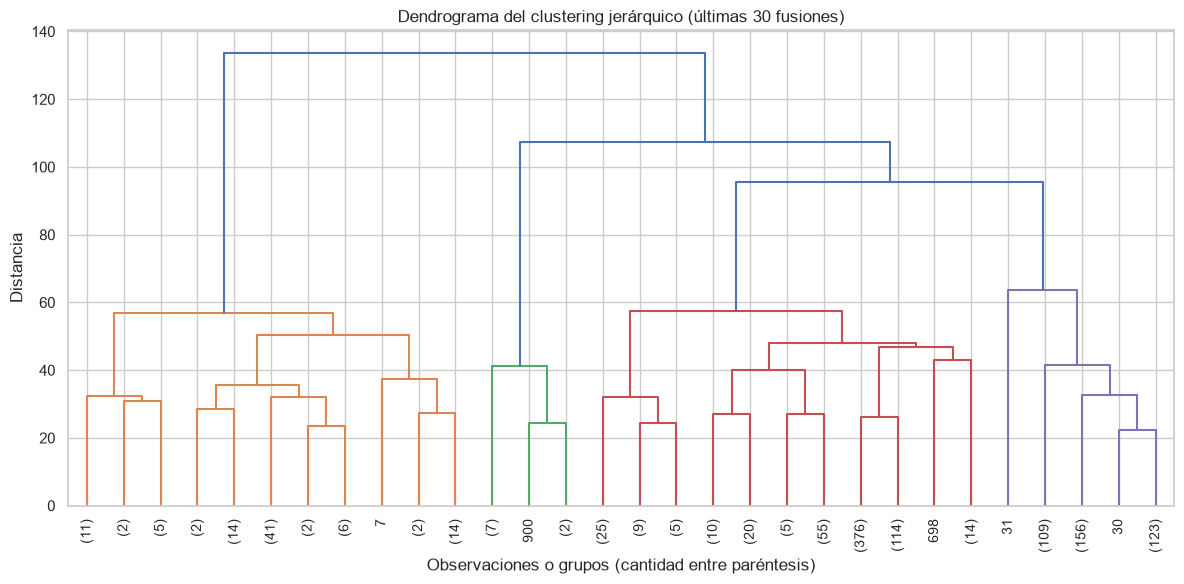

In [15]:
# Construir el árbol jerárquico con enlace Ward y distancia euclidiana.
# truncate_mode="lastp" limita la cantidad de ramas visibles para mejorar la legibilidad.
matriz_enlace = linkage(datos_estandarizados, method="ward", metric="euclidean")

plt.figure(figsize=(12, 6))
dendrogram(
    matriz_enlace,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=90
)
plt.title("Dendrograma del clustering jerárquico (últimas 30 fusiones)")
plt.xlabel("Observaciones o grupos (cantidad entre paréntesis)")
plt.ylabel("Distancia")
plt.tight_layout()
plt.show()


## 15. Modelo definitivo de clustering jerárquico

In [16]:
# ==========================================
# 21. MODELO DEFINITIVO DE CLUSTERING JERÁRQUICO
# ==========================================

# Crear el modelo jerárquico
modelo_jerarquico = AgglomerativeClustering(
    n_clusters=3,
    metric="euclidean",
    linkage="ward"
)

# Obtener las etiquetas
clusters_jerarquico = modelo_jerarquico.fit_predict(
    df_estandarizado
)

# Crear base con resultados
df_resultados_jerarquico = df[
    [
        "establecimiento_educativo",
        "sector",
        "sexo",
        "comuna_establecimiento"
    ]
].copy()

df_resultados_jerarquico["cluster_jerarquico"] = (
    clusters_jerarquico
)

# Distribución de registros
print("DISTRIBUCIÓN DE REGISTROS POR CLÚSTER:")

distribucion_jerarquica = (
    df_resultados_jerarquico["cluster_jerarquico"]
    .value_counts()
    .sort_index()
)

display(distribucion_jerarquica)

# Porcentajes
print("\nPORCENTAJE POR CLÚSTER:")

porcentajes_jerarquicos = (
    df_resultados_jerarquico["cluster_jerarquico"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

display(porcentajes_jerarquicos.round(2))

# Métricas definitivas
print("\nMÉTRICAS DEL MODELO JERÁRQUICO:")

print(
    "Silhouette:",
    round(
        silhouette_score(
            df_estandarizado,
            clusters_jerarquico
        ), 4
    )
)

print(
    "Davies-Bouldin:",
    round(
        davies_bouldin_score(
            df_estandarizado,
            clusters_jerarquico
        ), 4
    )
)

print(
    "Calinski-Harabasz:",
    round(
        calinski_harabasz_score(
            df_estandarizado,
            clusters_jerarquico
        ), 4
    )
)

print("\nPRIMEROS REGISTROS CLASIFICADOS:")
display(df_resultados_jerarquico.head(10))

DISTRIBUCIÓN DE REGISTROS POR CLÚSTER:


cluster_jerarquico
0    1024
1     100
2      10
Name: count, dtype: int64


PORCENTAJE POR CLÚSTER:


cluster_jerarquico
0    90.30
1     8.82
2     0.88
Name: proportion, dtype: float64


MÉTRICAS DEL MODELO JERÁRQUICO:
Silhouette: 0.5658
Davies-Bouldin: 1.1521
Calinski-Harabasz: 235.8415

PRIMEROS REGISTROS CLASIFICADOS:


,establecimiento_educativo,sector,sexo,comuna_establecimiento,cluster_jerarquico
0,inst educ jose maria velaz,oficial,hombres,2,0
1,inst educ jose maria velaz,oficial,mujeres,2,0
2,inst educ barrio santa cruz,oficial,hombres,2,0
3,inst educ barrio santa cruz,oficial,mujeres,2,1
4,col comfama - sede aranjuez,no oficial,hombres,4,0
5,col comfama - sede aranjuez,no oficial,mujeres,4,0
6,inst educ cefa,oficial,hombres,10,0
7,inst educ cefa,oficial,mujeres,10,1
8,inst educ jose maria bernal,oficial,hombres,16,0
9,inst educ jose maria bernal,oficial,mujeres,16,0


## 16. Caracterización de los clústeres jerárquicos

In [17]:
# ==========================================
# 22. CARACTERIZACIÓN DE CLÚSTERES JERÁRQUICOS
# ==========================================

# Seleccionar variables originales de matrícula y deserción
columnas_clustering = [
    col for col in df.columns
    if col.startswith(("matricula_", "desercion_"))
    and df[col].nunique() > 1
]

# Crear dataframe con variables y etiquetas
df_perfil_jerarquico = df[columnas_clustering].copy()

df_perfil_jerarquico["cluster_jerarquico"] = (
    clusters_jerarquico
)

# Calcular promedios por grupo
perfil_jerarquico = (
    df_perfil_jerarquico
    .groupby("cluster_jerarquico")[columnas_clustering]
    .mean()
)

print("PROMEDIO DE VARIABLES POR CLÚSTER:")
display(perfil_jerarquico.round(2))

# Calcular diferencias entre grupos
diferencias_jerarquicas = (
    perfil_jerarquico.max() - perfil_jerarquico.min()
).sort_values(ascending=False)

print("\n10 VARIABLES CON MAYORES DIFERENCIAS:")
display(diferencias_jerarquicas.head(10).round(2))

# Distribución por sector educativo
print("\nDISTRIBUCIÓN POR SECTOR EDUCATIVO:")
display(
    pd.crosstab(
        df_resultados_jerarquico["cluster_jerarquico"],
        df_resultados_jerarquico["sector"],
        normalize="index"
    ).mul(100).round(2)
)

# Distribución por sexo
print("\nDISTRIBUCIÓN POR SEXO:")
display(
    pd.crosstab(
        df_resultados_jerarquico["cluster_jerarquico"],
        df_resultados_jerarquico["sexo"],
        normalize="index"
    ).mul(100).round(2)
)

PROMEDIO DE VARIABLES POR CLÚSTER:


,desercion_grado_prejardin,desercion_grado_jardin,desercion_grado_transicion,desercion_grado_1,desercion_grado_2,desercion_grado_3,desercion_grado_4,desercion_grado_5,desercion_escuela_nueva,desercion_grado_6,...,matricula_grado_10,matricula_grado_11,matricula_grado_12,matricula_grado_13,matricula_grado_clei1,matricula_grado_clei2,matricula_grado_clei3,matricula_grado_clei4,matricula_grado_clei5,matricula_grado_clei6
cluster_jerarquico,,,,,,,,,,,,,,,,,,,,,
0,0.08,0.08,0.34,0.45,0.27,0.27,0.31,0.29,0.0,1.05,...,17.60,15.05,0.07,0.05,0.01,0.77,4.39,5.96,4.15,5.36
1,0.09,0.05,3.80,5.16,3.39,2.93,3.03,3.19,0.0,9.79,...,93.87,79.78,0.00,0.00,1.65,3.25,15.05,16.40,9.97,9.13
2,0.00,0.00,0.10,0.10,0.00,0.00,0.00,0.00,0.0,0.00,...,2.10,1.00,0.00,0.00,0.00,23.60,302.10,388.40,387.60,367.10



10 VARIABLES CON MAYORES DIFERENCIAS:


matricula_grado_clei5    383.45
matricula_grado_clei4    382.44
matricula_grado_clei6    361.74
matricula_grado_clei3    297.71
matricula_grado_6        134.21
matricula_grado_7        112.13
matricula_grado_5        101.53
matricula_grado_4        101.22
matricula_grado_8        101.07
matricula_grado_3        100.15
dtype: float64


DISTRIBUCIÓN POR SECTOR EDUCATIVO:


sector,cobertura contratada,no oficial,oficial,regimen especial
cluster_jerarquico,,,,
0,8.01,56.25,35.55,0.2
1,2.00,4.00,94.00,0.0
2,80.00,20.00,0.00,0.0



DISTRIBUCIÓN POR SEXO:


sexo,hombres,mujeres
cluster_jerarquico,,
0,50.0,50.0
1,49.0,51.0
2,60.0,40.0


## 17. Comparación reproducible de los tres algoritmos

COMPARACIÓN DE RESULTADOS CALCULADOS:


,Algoritmo,Clusters,Registros en ruido,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-means,3,0,0.4435,1.1627,295.6555
1,DBSCAN,2,105,0.5555,0.7014,28.2816
2,Jerárquico,3,0,0.5658,1.1521,235.8415


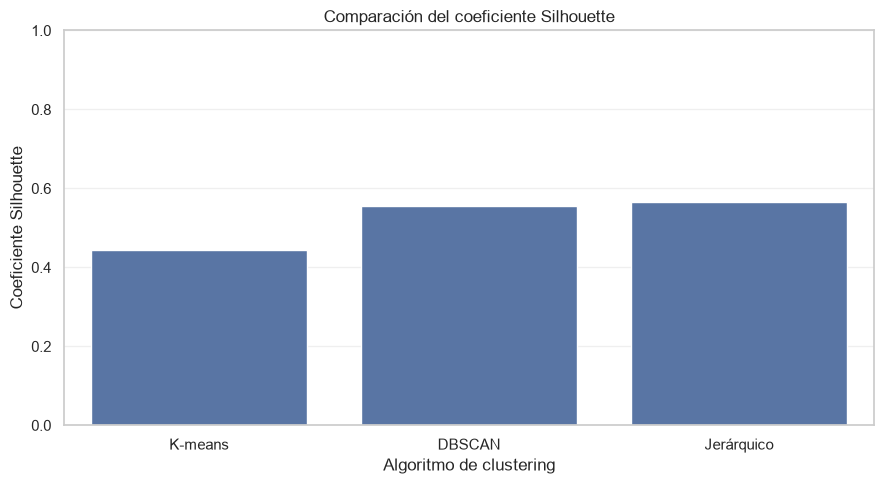

Nota: para DBSCAN las métricas se calculan sin incluir el ruido.


In [18]:
# Calcular las métricas directamente a partir de las etiquetas obtenidas.
# Para DBSCAN, las métricas se calculan excluyendo los registros etiquetados como ruido (-1).

def calcular_metricas(X, etiquetas, excluir_ruido=False):
    etiquetas = np.asarray(etiquetas)
    mascara = etiquetas != -1 if excluir_ruido else np.ones(len(etiquetas), dtype=bool)
    X_eval = np.asarray(X)[mascara]
    etiquetas_eval = etiquetas[mascara]
    n_grupos = len(set(etiquetas_eval))

    if n_grupos < 2 or n_grupos >= len(etiquetas_eval):
        return {"Silhouette": np.nan, "Davies-Bouldin": np.nan,
                "Calinski-Harabasz": np.nan}

    return {
        "Silhouette": silhouette_score(X_eval, etiquetas_eval),
        "Davies-Bouldin": davies_bouldin_score(X_eval, etiquetas_eval),
        "Calinski-Harabasz": calinski_harabasz_score(X_eval, etiquetas_eval)
    }

metricas_kmeans = calcular_metricas(datos_estandarizados, clusters_kmeans)
metricas_dbscan = calcular_metricas(datos_estandarizados, clusters_dbscan, excluir_ruido=True)
metricas_jerarquico = calcular_metricas(datos_estandarizados, clusters_jerarquico)

comparacion_modelos = pd.DataFrame([
    {
        "Algoritmo": "K-means",
        "Clusters": len(set(clusters_kmeans)),
        "Registros en ruido": 0,
        **metricas_kmeans
    },
    {
        "Algoritmo": "DBSCAN",
        "Clusters": len(set(clusters_dbscan) - {-1}),
        "Registros en ruido": int(np.sum(np.asarray(clusters_dbscan) == -1)),
        **metricas_dbscan
    },
    {
        "Algoritmo": "Jerárquico",
        "Clusters": len(set(clusters_jerarquico)),
        "Registros en ruido": 0,
        **metricas_jerarquico
    }
])

print("COMPARACIÓN DE RESULTADOS CALCULADOS:")
display(comparacion_modelos.round(4))

# Gráfica comparativa de Silhouette
plt.figure(figsize=(9, 5))
sns.barplot(data=comparacion_modelos, x="Algoritmo", y="Silhouette")
plt.title("Comparación del coeficiente Silhouette")
plt.xlabel("Algoritmo de clustering")
plt.ylabel("Coeficiente Silhouette")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Nota: para DBSCAN las métricas se calculan sin incluir el ruido.")


## 18. Visualización de los clústeres mediante PCA

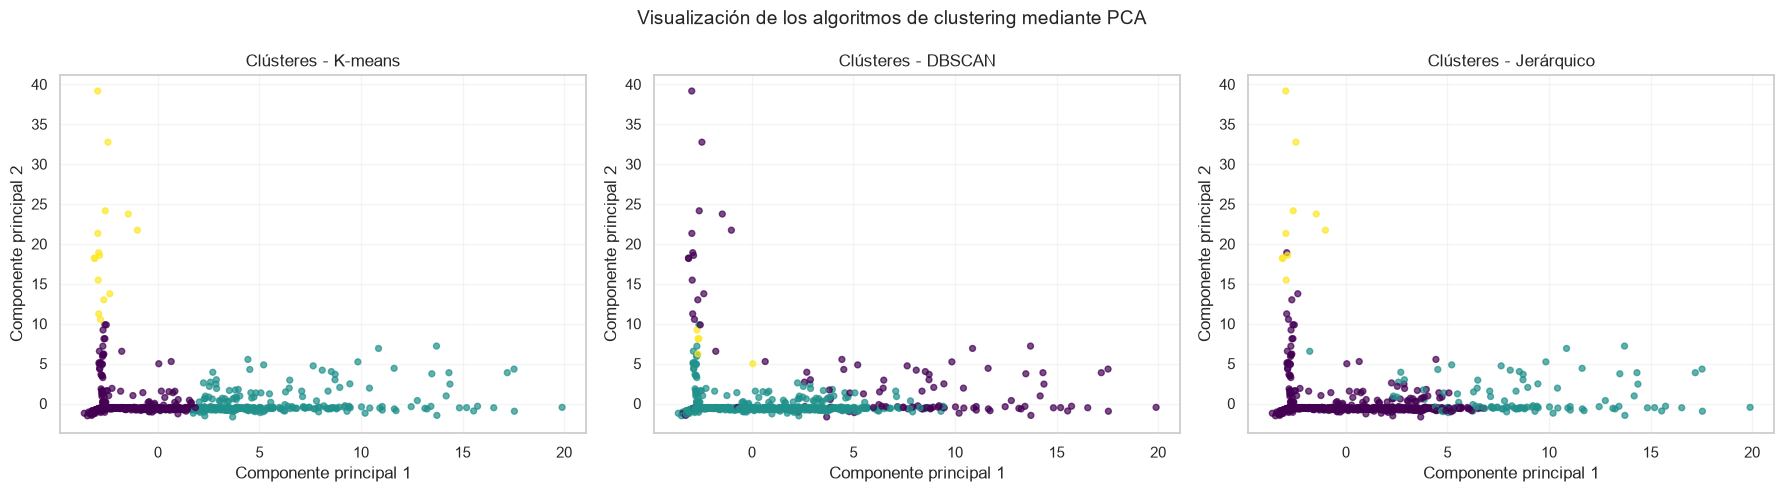

Varianza explicada por los dos componentes: 49.84 %


In [19]:
# ==========================================
# VISUALIZACIÓN DE CLÚSTERES MEDIANTE PCA
# ==========================================

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reducir los datos estandarizados a dos dimensiones
pca = PCA(n_components=2)
datos_pca = pca.fit_transform(datos_estandarizados)

# Preparar los resultados de cada algoritmo
modelos = [
    ("K-means", clusters_kmeans),
    ("DBSCAN", clusters_dbscan),
    ("Jerárquico", clusters_jerarquico)
]

# Crear una figura con tres gráficas
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (nombre, etiquetas) in zip(axes, modelos):

    ax.scatter(
        datos_pca[:, 0],
        datos_pca[:, 1],
        c=etiquetas,
        cmap="viridis",
        s=18,
        alpha=0.7
    )

    ax.set_title(f"Clústeres - {nombre}")
    ax.set_xlabel("Componente principal 1")
    ax.set_ylabel("Componente principal 2")
    ax.grid(alpha=0.2)

fig.suptitle(
    "Visualización de los algoritmos de clustering mediante PCA",
    fontsize=14
)

plt.tight_layout()
plt.show()

print(
    "Varianza explicada por los dos componentes:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

## 19. Consideraciones e interpretación

- Los clústeres representan similitudes entre registros según las variables numéricas de matrícula y deserción seleccionadas; no equivalen a categorías oficiales de calidad o riesgo.
- Los conteos absolutos pueden estar influidos por el tamaño de cada establecimiento. Para análisis posteriores conviene explorar tasas de deserción con denominadores claramente definidos.
- La base corresponde al año 2017, por lo que los resultados describen ese periodo y no necesariamente la situación actual.
- En DBSCAN, los registros con etiqueta `-1` se interpretan como ruido. Las métricas se calculan sobre los registros no considerados ruido y deben interpretarse teniendo en cuenta el tamaño y número de grupos encontrados.

## Referencia de los datos

Alcaldía de Medellín. (2017). *Deserción educativa*. MEData.  
https://medata.app.medellin.gov.co/sites/default/files/distribution/1-011-08-000065/desercion_educativa.csv
